# 08 · La popularité par pays

Questions de ce notebook :
1. quel est le Pokémon le plus populaire dans chaque pays ? (et est-ce qu'on retrouve l'étude de TheToyZone ?)
2. est-ce qu'on peut faire des groupes de pays qui ont les mêmes goûts ? (clustering du TP2, MDS et t-SNE du TP4)
3. est-ce que les pays voisins aiment les mêmes Pokémon ? (autocorrélation spatiale : Moran et LISA)

La seule source par pays, c'est **Google Trends** : les recherches sur les noms anglais, ramenées sur l'échelle de Gengar puis transformées en percentiles par pays dans le notebook 02 (on y a gardé les 67 pays qui ont assez de recherches). Ça mesure l'**attention** (ce que les gens cherchent), pas forcément l'affection. On garde aussi en tête les 17 noms ambigus repérés dans le notebook 02 (Persian, Durant, Ditto…) : on les garde comme les autres Pokémon, mais on les signale quand ils ressortent.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import pycountry

pd.set_option("display.max_columns", 50)
RAW = Path("../data/raw")
OUT = Path("../data/processed")
table = pd.read_csv(OUT / "table_maitre.csv", index_col="dex")
ratio = pd.read_csv(OUT / "trends_ratio_gengar_pays.csv", index_col="dex")
pct = pd.read_csv(OUT / "trends_percentile_pays.csv", index_col="dex")
ttz = pd.read_csv(RAW / "thetoyzone/favori_par_pays_et_generation.csv")
nom = table["nom_fr"]
print(ratio.shape, pct.shape, ttz.shape)

(1025, 171) (1025, 67) (853, 3)


## 1. Le Pokémon le plus cherché dans chaque pays

Dans chaque pays, le ratio à Gengar dit combien un Pokémon est cherché par rapport à Gengar. Le plus cherché, c'est celui qui a le plus grand ratio.

In [2]:
plus_cherche = ratio.idxmax()
plus_cherche.map(nom).value_counts().head(10)

Pikachu      63
Persian      45
Fermite      18
Électrode     8
Galekid       7
Onix          7
Métamorph     5
Arceus        4
Grolem        3
Ratentif      2
Name: count, dtype: int64

Sans surprise, **Pikachu est le plus cherché dans 63 pays sur 171**. Mais juste derrière, on retrouve les noms ambigus du notebook 02 : Persian (45 pays !), Fermite (*Durant*), Électrode, Galekid (*Aron*), Onix, Métamorph (*Ditto*)… Le « plus cherché » dit donc surtout « Pikachu, ou un mot courant ».

## 2. Le Pokémon « surreprésenté » (comme TheToyZone)

Comme le plus cherché c'est presque toujours le même, TheToyZone a pris une autre définition : le Pokémon dont **la part dans les recherches du pays dépasse le plus sa part dans le monde**.

- part dans le pays = ratio du Pokémon / somme des ratios de tous les Pokémon du pays ;
- part dans le monde : on n'a pas les volumes de recherche de chaque pays (Google Trends ne donne que du relatif), donc on prend **la moyenne des parts sur les pays** (chaque pays compte pareil) ;
- surreprésentation = part dans le pays / part dans le monde.

In [3]:
part = ratio / ratio.sum()
part_monde = part.mean(axis=1)
surrep = part.div(part_monde, axis=0)
surrep.stack().describe()

count    175203.000000
mean          1.000000
std           2.489771
min           0.000000
25%           0.000000
50%           0.307114
75%           1.598727
max         171.000000
dtype: float64

La surreprésentation vaut 1 en moyenne (normal, par construction). La médiane est à 0,3 parce que beaucoup de cases sont à 0, et le maximum monte à 171.

In [4]:
fav_surrep = surrep.idxmax()
print("nombre de Pokémon différents :", fav_surrep.nunique())
fav_surrep.map(nom).value_counts().head(10)

nombre de Pokémon différents : 126


Chongjian      5
Canarbello     5
Cliticlic      5
Flabébé        4
Aflamanoir     4
Luxio          3
Arrozard       3
Tissenboule    3
Hydragla       3
Dinglu         3
Name: count, dtype: int64

Avec cette définition brute, on obtient 126 favoris différents, et les premiers sont des Pokémon peu connus (Chongjian, Canarbello, Cliticlic…).

In [5]:
# le problème des petites valeurs : un Pokémon presque jamais cherché dans le monde mais un peu dans un pays a un énorme rapport
top = pd.DataFrame({"favori": fav_surrep.map(nom), "surrep": surrep.max(),
                    "part_monde_du_favori": part_monde[fav_surrep].values,
                    "pays_garde_notebook02": surrep.columns.isin(pct.columns)})
top.sort_values("surrep", ascending=False).head(10)

,favori,surrep,part_monde_du_favori,pays_garde_notebook02
Bermuda,Nidoran♀,171.000000,5.908200e-05,False
St. Helena,Nidoran♂,171.000000,1.035155e-06,False
Dominican Republic,Badabouin,171.000000,6.800902e-07,True
St. Lucia,Piclairon,164.350327,5.504743e-05,False
Caribbean Netherlands,Dolman,147.830879,4.004544e-04,False
Sint Maarten,Grotichon,147.588323,2.287900e-04,False
Panama,Macronium,124.273174,9.397398e-06,True
St. Kitts & Nevis,Polagriffe,120.386757,2.058870e-04,False
Antigua & Barbuda,Groret,116.534677,1.048624e-04,False
Macao,Virevorreur,115.937165,3.130399e-05,False


Les plus grosses surreprésentations valent exactement ou presque 171, le nombre de pays : ce sont des Pokémon qui ne sont cherchés que dans **un seul** pays (Nidoran♀ aux Bermudes, Badabouin en République dominicaine). Leur part dans le monde est minuscule (de l'ordre de 10⁻⁶), donc le moindre point de recherche les fait exploser.

In [6]:
top.groupby("pays_garde_notebook02")["surrep"].describe()

,count,mean,std,min,25%,50%,75%,max
pays_garde_notebook02,,,,,,,,
False,104.0,48.156872,40.194218,7.116097,16.634429,33.466621,71.776245,171.0
True,67.0,26.505231,28.316309,5.404258,13.811320,18.696773,25.040995,171.0


C'est pire dans les 104 petits pays écartés au notebook 02 (médiane 33) que dans les 67 pays gardés (médiane 19).

## 3. Comparaison avec TheToyZone

TheToyZone donne un favori par pays **et par génération** (pas de favori toutes générations). Pour comparer, on refait le même calcul à l'intérieur de chaque génération : on compare un Pokémon seulement aux Pokémon de sa génération.

In [7]:
print("pays TheToyZone :", ttz.pays.nunique())
manquants = sorted(set(ttz.pays) - set(ratio.columns))
print("pays TheToyZone absents de Google Trends (ou écrits autrement) :", manquants)

pays TheToyZone : 114
pays TheToyZone absents de Google Trends (ou écrits autrement) : ['Bosnia and Herzegovina', 'Cote d\\u2019Ivoire (Ivory Coast)', 'Czech Republic', 'Ireland (Republic of)', 'Macedonia (North)', 'Myanmar', 'Trinidad and Tobago', 'Turkey', 'United States of America']


9 pays de TheToyZone ne sont pas trouvés tels quels, mais ce sont presque tous des différences d'écriture (Czech Republic / Czechia, Turkey / Türkiye…).

In [8]:
nom_en_vers_dex = pd.Series(table.index, index=table["nom_en"].str.lower())
ttz["dex"] = ttz["pokemon"].str.lower().map(nom_en_vers_dex)
print("noms TheToyZone non reconnus :", ttz.loc[ttz.dex.isna(), "pokemon"].unique())

noms TheToyZone non reconnus : <StringArray>
['Sirfetch'd', 'Farfetch'd']
Length: 2, dtype: str


Côté Pokémon, seuls Farfetch'd et Sirfetch'd posent problème, à cause de l'apostrophe (droite chez TheToyZone, courbe dans PokéAPI).

In [9]:
# les noms de pays Google qui ressemblent à ceux qui manquent
[p for p in ratio.columns if any(m in p for m in ["Bosnia", "Ivoire", "Czech", "Ireland", "Macedonia", "Myanmar", "Trinidad", "Türk", "United States"])]

['Bosnia & Herzegovina',
 'Czechia',
 'Côte d’Ivoire',
 'Ireland',
 'Myanmar (Burma)',
 'North Macedonia',
 'Trinidad & Tobago',
 'Türkiye',
 'United States']

In [10]:
corr_pays = {"Bosnia and Herzegovina": "Bosnia & Herzegovina", "Cote d\\u2019Ivoire (Ivory Coast)": "Côte d’Ivoire",
             "Czech Republic": "Czechia", "Ireland (Republic of)": "Ireland", "Macedonia (North)": "North Macedonia",
             "Trinidad and Tobago": "Trinidad & Tobago", "Turkey": "Türkiye", "United States of America": "United States"}
ttz["pays_gt"] = ttz["pays"].replace(corr_pays)
ttz["dex"] = ttz["pokemon"].str.replace("'", "’").str.lower().map(nom_en_vers_dex)
print("pays encore absents :", sorted(set(ttz.pays_gt) - set(ratio.columns)))
print("noms non reconnus :", ttz.loc[ttz.dex.isna(), "pokemon"].unique())

pays encore absents : ['Myanmar']
noms non reconnus : <StringArray>
[]
Length: 0, dtype: str


Après correction, il ne reste que le Myanmar, qui n'est pas dans nos 171 pays sous ce nom (*Myanmar (Burma)*) et qui ne fait de toute façon pas partie des 67 pays gardés.

On a vu juste avant que la surreprésentation brute est dominée par les **Pokémon presque jamais cherchés** : si un Pokémon n'a une valeur que dans un seul pays, sa part dans ce pays divisée par sa part moyenne vaut à peu près le nombre de pays (171), le maximum possible. C'est du bruit des petites valeurs entières, pas une préférence.

Du coup on ajoute deux filtres :
- on ne garde que les **67 pays** fiables du notebook 02, parce que c'est dans les petits pays que le bruit est le pire (médiane 33 contre 19) ;
- un Pokémon ne peut être « favori » que s'il est cherché (ratio > 0) dans **au moins la moitié** de ces pays. On prend 50 % parce que c'est assez pour écarter les Pokémon fantômes qui n'existent que dans un pays, sans retirer les Pokémon peu connus mais cherchés un peu partout.

Pour la part dans le monde, on garde la moyenne des parts des pays (chaque pays compte pareil). On n'a pas le choix : Google Trends ne donne pas les volumes de recherche, donc on ne peut pas pondérer par la taille des pays comme TheToyZone.

In [11]:
MIN_PART_PAYS = 0.5   # le Pokémon doit avoir une valeur dans au moins 50 % des pays gardés

pays_ok = list(pct.columns)
r67 = ratio[pays_ok]
presence = (r67 > 0).mean(axis=1)
print("Pokémon qui passent le filtre :", (presence >= MIN_PART_PAYS).sum(), "sur", len(r67))

def favori_surrep(r, eligibles):
    p = r / r.sum()
    s = p.div(p.mean(axis=1), axis=0)
    return s.loc[eligibles].idxmax(), s.loc[eligibles].max()

eligibles = presence[presence >= MIN_PART_PAYS].index
fav67, val67 = favori_surrep(r67, eligibles)
print("nombre de favoris différents :", fav67.nunique())
fav67.map(nom).value_counts().head(10)

Pokémon qui passent le filtre : 988 sur 1025
nombre de favoris différents : 52


Onix           5
Roue-de-Fer    3
Tic            3
Luxio          3
Électrode      2
Muciole        2
Grotadmorv     2
Voltoutou      2
Munna          2
Lombre         1
Name: count, dtype: int64

Le filtre « cherché dans au moins 50 % des pays » ne retire que 37 Pokémon sur 1 025, mais ça suffit : on passe à 52 favoris différents. Onix arrive en tête (5 pays), puis Roue-de-Fer, Tic et Luxio (3 pays chacun).

In [12]:
pd.DataFrame({"favori": fav67.map(nom), "surrep": val67.round(1)}).sort_values("surrep", ascending=False).head(15)

,favori,surrep
Romania,Ratentif,63.7
Türkiye,Yanma,58.1
Finland,Négapi,51.2
France,Otarlette,48.7
South Africa,Mascaïman,47.4
Bangladesh,Pandespiègle,26.2
Ireland,Lombre,24.6
Pakistan,Otaria,20.7
Russia,Luxio,20.4
Indonesia,Luxio,20.1


Les plus fortes surreprésentations restent des cas bizarres : Ratentif en Roumanie (×64), Yanma en Turquie (×58), Négapi en Finlande (×51), Otarlette en France (×49), Mascaïman en Afrique du Sud (×47).

### Comparaison par génération

Même calcul, mais à l'intérieur de chaque génération (on ne compare un Pokémon qu'aux Pokémon de sa génération), sur les pays qu'on a en commun avec TheToyZone.

In [13]:
lignes = []
for g in range(1, 10):
    dex_g = table.index[table.generation == g]
    rg = r67.loc[dex_g]
    elig_g = [d for d in dex_g if presence[d] >= MIN_PART_PAYS]
    fav_g, _ = favori_surrep(rg, elig_g)
    elig_tous = list(dex_g)
    fav_g_sans_filtre, _ = favori_surrep(rg[rg.sum(axis=1) > 0], [d for d in dex_g if rg.loc[d].sum() > 0])
    t = ttz[(ttz.generation == g) & ttz.pays_gt.isin(pays_ok)].set_index("pays_gt")["dex"]
    commun = t.index
    lignes.append({"generation": g, "pays_communs": len(commun),
                   "accord_avec_filtre": (fav_g[commun].values == t.values).mean(),
                   "accord_sans_filtre": (fav_g_sans_filtre[commun].values == t.values).mean()})
accord = pd.DataFrame(lignes).set_index("generation")
accord.round(2)

,pays_communs,accord_avec_filtre,accord_sans_filtre
generation,,,
1,65,0.20,0.18
2,65,0.26,0.25
3,65,0.12,0.11
4,65,0.09,0.08
5,65,0.08,0.03
6,65,0.15,0.12
7,65,0.12,0.12
8,65,0.05,0.03
9,54,0.02,0.00


**L'accord avec TheToyZone est faible** : 12 % des pays en moyenne avec le filtre (20 % en génération 1, 26 % en génération 2, mais 2 à 9 % pour les générations 4, 5, 8 et 9). Sans le filtre c'est encore un peu plus bas (10 %).

In [14]:
print("accord moyen (avec filtre) :", round(accord.accord_avec_filtre.mean(), 2), "| sans filtre :", round(accord.accord_sans_filtre.mean(), 2))
# combien de favoris différents chez TheToyZone, par génération ?
ttz.groupby("generation")["dex"].nunique()

accord moyen (avec filtre) : 0.12 | sans filtre : 0.1


generation
1    49
2    40
3    57
4    49
5    67
6    41
7    42
8    34
9    26
Name: dex, dtype: int64

TheToyZone a lui-même beaucoup de favoris différents (de 26 à 67 selon la génération), donc il n'y a pas un favori évident par génération qu'on aurait raté.

In [15]:
# exemple : la génération 1, nos favoris et ceux de TheToyZone côte à côte
g = 1
dex_g = table.index[table.generation == g]
fav_g1, _ = favori_surrep(r67.loc[dex_g], [d for d in dex_g if presence[d] >= MIN_PART_PAYS])
t = ttz[(ttz.generation == g) & ttz.pays_gt.isin(pays_ok)].set_index("pays_gt")["dex"]
comp = pd.DataFrame({"nous": fav_g1[t.index].map(nom), "TheToyZone": t.map(nom)})
comp.head(20)

,nous,TheToyZone
Argentina,Onix,Aquali
Australia,Grotadmorv,Grotadmorv
Austria,Grotadmorv,Grotadmorv
Bangladesh,Nosferalto,Grotadmorv
Belgium,Poissoroy,Doduo
Bolivia,Abra,Abra
Brazil,Onix,Roucoups
Bulgaria,Hypnomade,Grotadmorv
Canada,Persian,Flagadoss
Chile,Sabelette,Aquali


Quand on compare pays par pays en génération 1, on retrouve parfois le même favori (Grotadmorv en Australie, Autriche, Tchéquie ; Tadmorv au Danemark ; Abra en Bolivie ; Scarabrute en République dominicaine). Ailleurs, c'est souvent un nom ambigu chez nous (Onix, Persian) qui prend la place. Les écarts viennent aussi de la méthode : TheToyZone a des volumes de recherche absolus (outil Ahrefs) alors que nous n'avons que du relatif avec des petits entiers.

## 4. L'effet des noms ambigus

Dans le notebook 02, on a repéré 17 noms anglais qui sont aussi des mots courants, des prénoms ou des marques (Persian, Durant, Klink, Ditto, Onix…) : pour eux, Google compte aussi les recherches sur le mot, pas seulement sur le Pokémon. On reprend la liste du notebook 02 et on regarde combien de « favoris » ils touchent.

In [16]:
pop = pd.read_csv(OUT / "popularite_sources.csv", index_col="dex")
dex_ambigus = pop.index[pop["trends_nom_ambigu"]]
print(len(dex_ambigus), "noms ambigus :", ", ".join(nom[dex_ambigus]))
print("pays dont le plus cherché est un nom ambigu :", plus_cherche[pays_ok].isin(dex_ambigus).sum(), "sur", len(pays_ok))
print("pays dont le favori surreprésenté est un nom ambigu :", fav67.isin(dex_ambigus).sum(), "sur", len(pays_ok))
print(pd.Series(fav67[fav67.isin(dex_ambigus)].map(nom)).value_counts())

17 noms ambigus : Paras, Persian, Abra, Grolem, Onix, Électrode, Métamorph, Mew, Yanma, Galekid, Négapi, Ratentif, Munna, Mascaïman, Tic, Clic, Fermite
pays dont le plus cherché est un nom ambigu : 34 sur 67
pays dont le favori surreprésenté est un nom ambigu : 21 sur 67
Onix         5
Tic          3
Électrode    2
Munna        2
Négapi       1
Paras        1
Mascaïman    1
Persian      1
Ratentif     1
Galekid      1
Yanma        1
Abra         1
Grolem       1
Name: count, dtype: int64


Les noms ambigus touchent **34 pays sur 67 pour le plus cherché**, et **21 pays sur 67 pour le favori surreprésenté**. Onix (5 pays) est le plus fréquent, et ce n'est pas un hasard : la Chevrolet Onix est une voiture très vendue en Amérique du Sud. Ratentif (*Patrat*) et Négapi (*Minun*) ont été ajoutés à la liste après avoir vu leurs scores en Roumanie et en Finlande.

In [17]:
# juste pour voir : qu'est-ce qui changerait si on les enlevait ?
r_sans = r67.drop(index=dex_ambigus)
plus_cherche_sans = r_sans.idxmax()
fav_sans, val_sans = favori_surrep(r_sans, [d for d in eligibles if d not in dex_ambigus])
print("plus cherché sans les noms ambigus :")
print(plus_cherche_sans.map(nom).value_counts().head(8))
print("favori surreprésenté : pays qui changent :", (fav_sans != fav67).sum(), "sur", len(pays_ok))

plus cherché sans les noms ambigus :
Pikachu    61
Arceus      4
Luxio       1
Otaria      1
Name: count, dtype: int64
favori surreprésenté : pays qui changent : 22 sur 67


Sans les noms ambigus, Pikachu devient le plus cherché dans 61 pays sur 67 (Arceus dans 4). Le favori surreprésenté change dans 22 pays sur 67.

Malgré ça, **on garde les noms ambigus dans toute la suite** (carte, clustering, Moran) : ce sont des Pokémon comme les autres, et les enlever ferait des trous. On les signale simplement dans les résultats (colonne « nom ambigu » dans le tableau des favoris et dans le survol de la carte), pour savoir quand un résultat peut venir du mot plutôt que du Pokémon.

## 5. La carte

Il faut passer des noms de pays de Google aux codes ISO à 3 lettres (ce que demandent plotly et les contours de pays). On utilise `pycountry`, et on vérifie ceux qu'il ne trouve pas.

In [18]:
def iso3(p):
    try:
        return pycountry.countries.lookup(p).alpha_3
    except LookupError:
        try:
            return pycountry.countries.search_fuzzy(p)[0].alpha_3
        except LookupError:
            return None

codes = pd.Series({p: iso3(p) for p in ratio.columns})
print("pays sans code :", codes[codes.isna()].index.tolist())
# on vérifie à l'œil les pays dont le nom Google ne correspond pas exactement au nom pycountry
verif = pd.DataFrame({"code": codes.dropna(), "nom_pycountry": [pycountry.countries.get(alpha_3=c).name for c in codes.dropna()]})
verif[verif.index != verif.nom_pycountry]

pays sans code :

 ['Antigua & Barbuda', 'Bosnia & Herzegovina', 'Cape Verde', 'Caribbean Netherlands', 'Côte d’Ivoire', 'Myanmar (Burma)', 'St. Helena', 'St. Kitts & Nevis', 'St. Lucia', 'Trinidad & Tobago', 'U.S. Virgin Islands']


,code,nom_pycountry
Bolivia,BOL,"Bolivia, Plurinational State of"
Brunei,BRN,Brunei Darussalam
Iran,IRN,"Iran, Islamic Republic of"
Kosovo,SRB,Serbia
Laos,LAO,Lao People's Democratic Republic
Moldova,MDA,"Moldova, Republic of"
Palestine,PSE,"Palestine, State of"
Russia,RUS,Russian Federation
Sint Maarten,NLD,Netherlands
South Korea,KOR,"Korea, Republic of"


In [19]:
# corrections à la main : les pays non trouvés, et deux erreurs de la recherche approchée (Kosovo → Serbie, Sint Maarten → Pays-Bas)
codes = codes.copy()
codes.update(pd.Series({"Antigua & Barbuda": "ATG", "Bosnia & Herzegovina": "BIH", "Cape Verde": "CPV", "Caribbean Netherlands": "BES",
                        "Côte d’Ivoire": "CIV", "Myanmar (Burma)": "MMR", "St. Helena": "SHN", "St. Kitts & Nevis": "KNA",
                        "St. Lucia": "LCA", "Trinidad & Tobago": "TTO", "U.S. Virgin Islands": "VIR",
                        "Kosovo": "XKX", "Sint Maarten": "SXM"}))
print("pays sans code :", codes[codes.isna()].index.tolist())
print("codes en double :", codes[codes.duplicated(keep=False)].to_dict())

pays sans code : []
codes en double : {}


Tous les pays ont maintenant un code ISO, sans doublon.

In [20]:
fav_s, val_s = favori_surrep(r67, eligibles)
plus_ch = r67.idxmax()
carte = pd.DataFrame({"pays": pays_ok, "iso3": codes[pays_ok].values,
                      "plus_cherche": plus_ch.map(nom).values,
                      "plus_cherche_ambigu": plus_ch.isin(dex_ambigus).values,
                      "favori_surrep": fav_s.map(nom).values,
                      "favori_ambigu": fav_s.isin(dex_ambigus).values,
                      "surrep": val_s.round(1).values})
carte["generation_favori"] = table.loc[fav_s.values, "generation"].values
fig = px.choropleth(carte, locations="iso3", color="generation_favori", hover_name="pays",
                    hover_data=["favori_surrep", "favori_ambigu", "surrep", "plus_cherche", "plus_cherche_ambigu"], color_continuous_scale="viridis",
                    title="Pokémon surreprésenté dans chaque pays (couleur = sa génération)")
fig.show()
carte.sort_values("pays").head(67)

,pays,iso3,plus_cherche,plus_cherche_ambigu,favori_surrep,favori_ambigu,surrep,generation_favori
44,Argentina,ARG,Onix,True,Onix,True,4.6,1
7,Australia,AUS,Persian,True,Roue-de-Fer,False,3.4,9
59,Austria,AUT,Pikachu,False,Muciole,False,14.4,3
46,Bangladesh,BGD,Persian,True,Pandespiègle,False,26.2,6
18,Belgium,BEL,Pikachu,False,Tic,True,5.6,5
...,...,...,...,...,...,...,...,...
2,United Kingdom,GBR,Persian,True,Tomberro,False,3.3,9
11,United States,USA,Persian,True,Roc-de-Fer,False,3.7,9
30,Uruguay,URY,Onix,True,Onix,True,7.3,1
45,Venezuela,VEN,Pikachu,False,Pomdepik,False,6.2,2


In [21]:
carte["generation_favori"].value_counts().sort_index()

generation_favori
1    15
2     5
3    10
4     6
5     9
6     2
7     4
8     5
9    11
Name: count, dtype: int64

Les favoris surreprésentés viennent de toutes les générations. La génération 1 arrive en tête (15 pays), mais c'est en partie à cause des noms ambigus : Onix, Électrode, Abra, Persian… sont de la génération 1. Viennent ensuite la génération 9 (11 pays) et la génération 3 (10 pays). La surreprésentation fait surtout ressortir des Pokémon de niche propres à chaque pays, plus qu'une vraie nostalgie.

## 6. Des groupes de pays qui ont les mêmes goûts ?

Dans le notebook 02, on a vu que les pays se ressemblent énormément (Spearman médian 0,88 entre deux pays) : tout le monde cherche à peu près les mêmes Pokémon. Si on fait le clustering sur les percentiles bruts, ce fond commun va tout écraser et on ne verra que des groupes « gros pays / petits pays ».

Du coup on **retire le fond commun** : pour chaque Pokémon, on enlève son percentile moyen sur les pays. Il reste, pour chaque pays, « ce Pokémon est plus (ou moins) cherché ici qu'en moyenne ». C'est le même esprit que la surreprésentation de TheToyZone, mais sur tous les Pokémon d'un coup.

On garde les 67 pays fiables et seulement les Pokémon cherchés dans au moins 50 % des pays (même filtre qu'avant, pour la même raison : les Pokémon presque jamais cherchés ne font que du bruit).

In [22]:
P = pct.loc[eligibles]                      # Pokémon × pays
# il reste quelques trous : les lots où Gengar n'avait pas de valeur dans un pays (notebook 02)
print("cases vides :", int(P.isna().sum().sum()), "dans", int((P.isna().sum() > 0).sum()), "pays")
X = P.sub(P.mean(axis=1), axis=0).T      # pays × Pokémon, fond commun retiré
X = X.fillna(0)                          # une case vide = « comme la moyenne des pays »
print(X.shape)
X.iloc[:5, :5]

cases vides : 7 dans 2 pays
(67, 988)


dex,1,2,3,4,5
Ireland,0.005754,0.018762,0.021761,0.005034,-0.010291
Thailand,-0.020099,-0.205628,0.004200,-0.024723,-0.245901
United Kingdom,0.006730,0.099250,0.019810,0.007960,0.024343
Finland,0.011547,0.081947,0.025503,0.001047,-0.110397
Portugal,0.003803,-0.110994,-0.004581,0.008936,-0.006876


Il n'y a que 7 cases vides (dans 2 pays) : ce sont les lots où Gengar n'avait pas de valeur. On les remplit par 0, c'est-à-dire « comme la moyenne des pays », parce que c'est le choix le plus neutre et que 7 cases sur plus de 66 000 ne peuvent pas changer le résultat. On a 67 pays décrits chacun par 988 Pokémon.

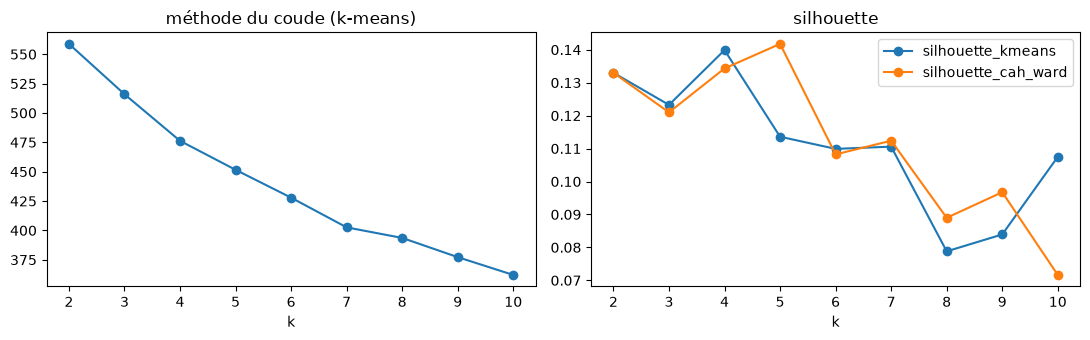

,inertie_kmeans,silhouette_kmeans,silhouette_cah_ward
k,,,
2,558.808,0.133,0.133
3,515.949,0.123,0.121
4,476.263,0.140,0.134
5,451.608,0.114,0.142
6,427.884,0.110,0.108
7,402.598,0.111,0.112
8,393.596,0.079,0.089
9,377.261,0.084,0.097
10,362.092,0.107,0.072


In [23]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X)
    cah = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    scores.append({"k": k, "inertie_kmeans": km.inertia_, "silhouette_kmeans": silhouette_score(X, km.labels_),
                   "silhouette_cah_ward": silhouette_score(X, cah.labels_)})
scores = pd.DataFrame(scores).set_index("k")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
scores["inertie_kmeans"].plot(ax=axes[0], marker="o", title="méthode du coude (k-means)")
scores[["silhouette_kmeans", "silhouette_cah_ward"]].plot(ax=axes[1], marker="o", title="silhouette")
plt.tight_layout()
plt.show()
scores.round(3)

La silhouette est **faible partout** (entre 0,07 et 0,14). Le coude n'est pas net non plus. Les groupes de pays existent mais ils ne sont pas très séparés : c'est cohérent avec le notebook 02, où tous les pays se ressemblaient beaucoup.

Du coup on ne peut pas vraiment choisir k avec la silhouette seule : k = 2, 4 et 5 sont presque à égalité (0,13 à 0,14). **On prend k = 4** : c'est le meilleur score pour le k-means (0,140), presque le même pour la CAH (0,134), et on va voir que ça donne des groupes qui ont un sens (avec k = 2 on aurait juste « Amérique latine / reste du monde »).

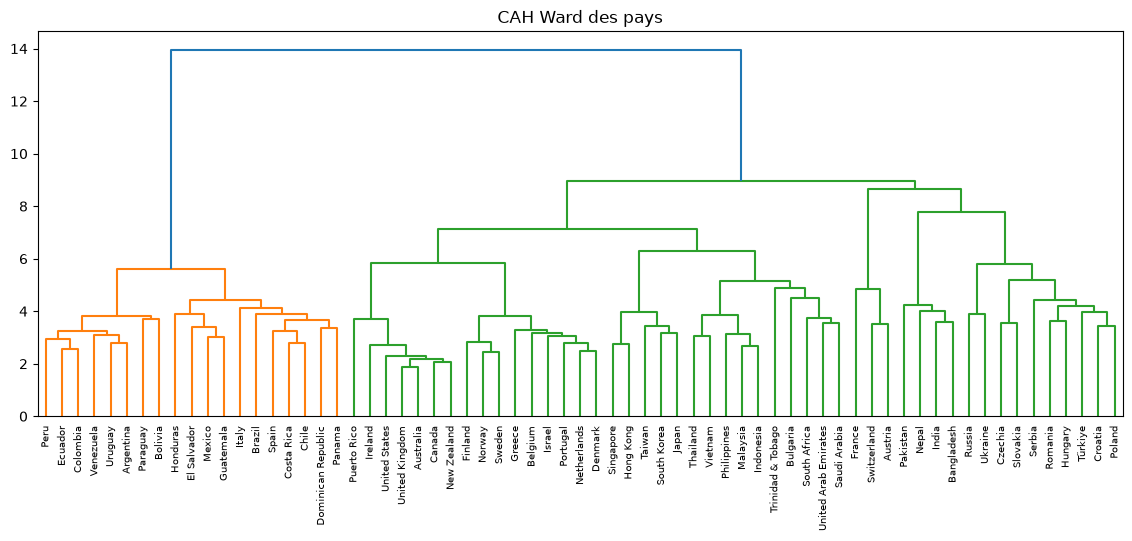

In [24]:
Z = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, labels=X.index.tolist(), leaf_font_size=7, ax=ax)
ax.set_title("CAH Ward des pays")
plt.show()

In [25]:
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(X)
cah = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
groupes = pd.DataFrame({"kmeans": km.labels_, "cah": cah.labels_}, index=X.index)
print("silhouette k-means :", round(silhouette_score(X, km.labels_), 3), "| CAH :", round(silhouette_score(X, cah.labels_), 3))
pd.crosstab(groupes.kmeans, groupes.cah)

silhouette k-means : 0.14 | CAH : 0.134


cah,0,1,2,3
kmeans,,,,
0,8,0,7,0
1,6,1,24,0
2,0,18,0,0
3,0,0,0,3


Avec k = 4, k-means et CAH sont d'accord sur deux groupes : les 18 pays d'Amérique latine et les 3 pays France, Suisse, Autriche. Par contre ils coupent autrement le reste des pays. On garde la **CAH Ward** pour la suite, parce que le dendrogramme permet de voir comment les groupes se forment et que ses groupes sont plus faciles à interpréter.

In [26]:
for g, d in groupes.groupby("cah"):
    print(f"groupe {g} ({len(d)} pays) :", ", ".join(d.index))

groupe 0 (14 pays) : Russia, Romania, Croatia, India, Hungary, Bangladesh, Pakistan, Poland, Türkiye, Czechia, Ukraine, Slovakia, Nepal, Serbia
groupe 1 (19 pays) : Spain, Dominican Republic, Italy, Uruguay, Costa Rica, Chile, Panama, Peru, Brazil, Argentina, Venezuela, Ecuador, Honduras, Colombia, Mexico, Guatemala, El Salvador, Paraguay, Bolivia
groupe 2 (31 pays) : Ireland, Thailand, United Kingdom, Finland, Portugal, Vietnam, Canada, Australia, Norway, Philippines, United States, New Zealand, Israel, Malaysia, South Korea, Sweden, Netherlands, Belgium, Denmark, Singapore, Greece, Puerto Rico, Indonesia, South Africa, United Arab Emirates, Taiwan, Hong Kong, Japan, Saudi Arabia, Trinidad & Tobago, Bulgaria
groupe 3 (3 pays) : France, Switzerland, Austria


Les groupes de la CAH sont très **géographiques et linguistiques**, alors que le clustering ne connaît pas la position des pays :
- **groupe 0** (14 pays) : l'**Europe de l'Est** (Russie, Ukraine, Pologne, Roumanie, Tchéquie…), la Turquie et l'**Asie du Sud** (Inde, Bangladesh, Pakistan, Népal) ;
- **groupe 1** (19 pays) : toute l'**Amérique latine**, plus l'Espagne et l'Italie ;
- **groupe 2** (31 pays) : le « reste du monde », pays anglophones, Europe du Nord et de l'Ouest, Asie de l'Est ;
- **groupe 3** (3 pays) : **France, Suisse, Autriche**.

In [27]:
# ce qui distingue chaque groupe : les Pokémon les plus au-dessus de la moyenne dans le groupe
moy = X.groupby(groupes.cah).mean().T
for g in moy.columns:
    t = moy[g].sort_values(ascending=False).head(8)
    print(f"groupe {g} :", ", ".join(f"{nom[d]} (+{v:.2f})" for d, v in t.items()))

groupe 0 : Charmillon (+0.33), Chef-de-Fer (+0.26), Hotte-de-Fer (+0.23), Vert-de-Fer (+0.18), Ratentif (+0.18), Dodoala (+0.18), Paume-de-Fer (+0.17), Poissoroy (+0.17)
groupe 1 : Akwakwak (+0.22), Germignon (+0.20), Nirondelle (+0.16), Gaulet (+0.16), Crocorible (+0.14), Chrysacier (+0.14), Mascaïman (+0.14), Grainipiot (+0.13)
groupe 2 : Rugit-Lune (+0.15), Vert-de-Fer (+0.14), Garde-de-Fer (+0.13), Flamenroule (+0.13), Paume-de-Fer (+0.12), Épine-de-Fer (+0.11), Tartard (+0.11), Sabelette (+0.11)
groupe 3 : Otarlette (+0.47), Luminéon (+0.44), Octillery (+0.42), Hippopotas (+0.41), Yanmega (+0.40), Ratentif (+0.40), Azurill (+0.39), Armaldo (+0.38)


Ce qui distingue chaque groupe :
- groupe 0 (Europe de l'Est, Asie du Sud) : Charmillon, plusieurs Pokémon Paradoxe de la génération 9 (Chef-de-Fer, Hotte-de-Fer, Vert-de-Fer…), Ratentif (le mot roumain « pătrat ») ;
- groupe 1 (Amérique latine) : des Pokémon anciens et des formes de base (Akwakwak, Germignon, Nirondelle, Chrysacier, Grainipiot…), et Mascaïman, qui est un nom ambigu ;
- groupe 2 (reste du monde) : des Pokémon Paradoxe et légendaires récents (Rugit-Lune, Garde-de-Fer…), avec des écarts plus faibles (+0,11 à +0,15) ;
- groupe 3 (France, Suisse, Autriche) : des Pokémon de génération 2 à 4 peu connus (Otarlette, Luminéon, Octillery, Hippopotas…), avec des écarts très forts (+0,38 à +0,47 de percentile).

Une piste pour le groupe France / Suisse / Autriche : dans ces pays, on cherche en français ou en allemand, et les noms anglais (ceux de notre collecte) sont moins tapés. Il reste alors peu de recherches, et les petites valeurs prennent beaucoup de place.

In [28]:
# la génération des Pokémon surreprésentés : est-ce qu'un groupe est plus « nostalgique » ?
gen = table.loc[X.columns, "generation"]
X.T.groupby(gen).mean().T.groupby(groupes.cah).mean().round(3)

generation,1,2,3,4,5,6,7,8,9
cah,,,,,,,,,
0,0.002,-0.009,0.001,-0.012,0.011,-0.008,0.022,0.006,-0.021
1,0.008,0.012,0.024,0.001,0.023,0.006,-0.017,-0.013,-0.060
2,-0.001,-0.008,-0.017,0.003,-0.017,0.003,0.001,0.006,0.043
3,-0.050,0.047,0.022,0.024,-0.027,-0.026,-0.010,-0.010,0.037


Par génération, l'Amérique latine (groupe 1) cherche moins la génération 9 (−0,06) et un peu plus les générations 3 et 5. Le reste du monde (groupe 2) cherche plus la génération 9 (+0,04). Le groupe France / Suisse / Autriche cherche moins la génération 1 (−0,05) et plus la génération 2 (+0,05).

## 7. MDS et t-SNE des pays (TP4)

On place les pays sur une carte 2D où deux pays proches ont des goûts proches. La distance entre deux pays = 1 − corrélation de Spearman entre leurs profils (fond commun retiré).

Pour le t-SNE, on prend une **perplexité de 10** au lieu de 30 (la valeur par défaut) : la perplexité, c'est en gros le nombre de voisins que chaque point « regarde », et avec seulement 67 pays, 30 reviendrait à regarder presque la moitié des pays.

stress de Kruskal : 0.284


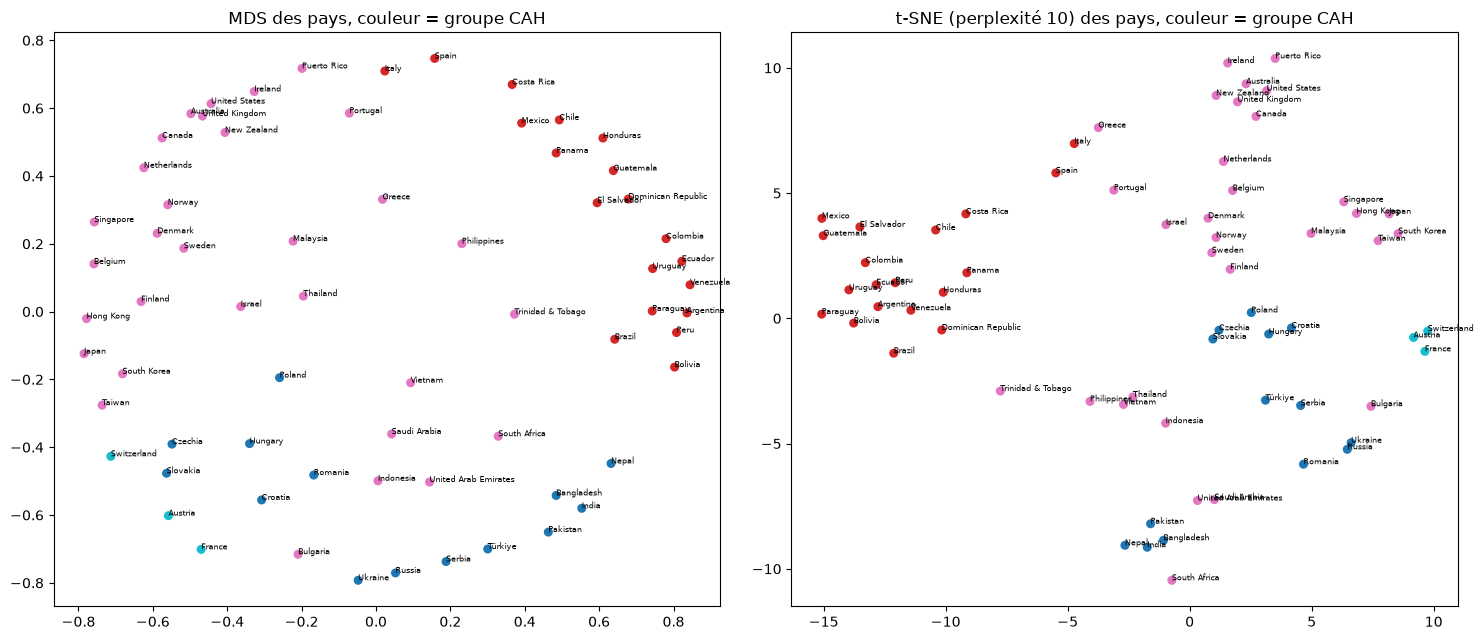

In [29]:
from sklearn.manifold import MDS, TSNE

D = 1 - X.T.corr(method="spearman")
mds = MDS(n_components=2, metric="precomputed", init="classical_mds", random_state=0)
coord_mds = pd.DataFrame(mds.fit_transform(D.values), index=X.index, columns=["mds1", "mds2"])
# stress de Kruskal (0 = distances parfaitement respectées ; au-dessus de 0,2 la carte déforme beaucoup)
d_2d = np.sqrt(((coord_mds.values[:, None, :] - coord_mds.values[None, :, :]) ** 2).sum(-1))
print("stress de Kruskal :", round(np.sqrt(((D.values - d_2d) ** 2).sum() / (D.values ** 2).sum()), 3))
tsne = TSNE(n_components=2, metric="precomputed", init="random", perplexity=10, random_state=0)
coord_tsne = pd.DataFrame(tsne.fit_transform(D.values), index=X.index, columns=["tsne1", "tsne2"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, cdf, titre in [(axes[0], coord_mds, "MDS"), (axes[1], coord_tsne, "t-SNE (perplexité 10)")]:
    ax.scatter(cdf.iloc[:, 0], cdf.iloc[:, 1], c=groupes.cah, cmap="tab10", s=30)
    for p, (a, b) in cdf.iterrows():
        ax.annotate(p, (a, b), fontsize=6)
    ax.set_title(titre + " des pays, couleur = groupe CAH")
plt.tight_layout()
plt.show()

Le **stress de Kruskal vaut 0,28** : la carte 2D déforme pas mal les vraies distances entre pays (on considère souvent qu'au-dessus de 0,2, c'est médiocre). On garde quand même la MDS, mais on lit surtout son premier axe, et on ne tire pas de conclusion sur la distance exacte entre deux pays.

In [30]:
# MDS1 : de quoi il s'agit ? on regarde les Pokémon les plus liés à l'axe
lien = X.corrwith(coord_mds["mds1"], method="spearman")
print("côté positif :", ", ".join(nom[d] for d in lien.sort_values(ascending=False).head(10).index))
print("côté négatif :", ", ".join(nom[d] for d in lien.sort_values().head(10).index))
print("pays aux extrémités :", coord_mds.mds1.sort_values().index[:5].tolist(), "...", coord_mds.mds1.sort_values().index[-5:].tolist())

côté positif : Roucool, Arcko, Draby, Mascaïman, Dynavolt, Kraknoix, Poussifeu, Nirondelle, Griknot, Crocorible
côté négatif : Reshiram, Ampibidou, Rugit-Lune, Prismillon, Zekrom, Zacian, Morpeko, Garde-de-Fer, Lestombaile, Fort-Ivoire
pays aux extrémités : ['Japan', 'Hong Kong', 'Belgium', 'Singapore', 'Taiwan'] ... ['Bolivia', 'Peru', 'Ecuador', 'Argentina', 'Venezuela']


L'axe MDS 1 va de **Japon, Hong Kong, Singapour, Belgique, Taïwan** d'un côté à **Bolivie, Pérou, Équateur, Argentine, Venezuela** de l'autre. Côté Amérique latine, on trouve des formes de base anciennes (Arcko, Roucool, Draby, Poussifeu…). De l'autre côté, ce sont des légendaires et des Pokémon récents (Reshiram, Zacian, Zekrom, Rugit-Lune…).

In [31]:
carte["groupe"] = carte["pays"].map(groupes.cah).astype(str)
fig = px.choropleth(carte, locations="iso3", color="groupe", hover_name="pays", title="Groupes de pays (CAH Ward, k = 4)")
fig.show()

## 8. Les pays voisins ont-ils les mêmes goûts ? (Moran et LISA)

L'**autocorrélation spatiale**, c'est la question : est-ce qu'une valeur dans un pays ressemble à la valeur dans les pays voisins ?
- l'**indice de Moran (I)** répond pour toute la carte d'un coup : I proche de 0 = pas de lien avec les voisins, I positif = les voisins se ressemblent ;
- le **LISA** (Moran local) répond pays par pays : il repère les pays qui ont une valeur haute entourés de voisins hauts (HH), basse entourés de bas (LL), ou les exceptions (HL, LH). La significativité est testée en mélangeant les valeurs au hasard entre pays (permutations).

**Les variables testées.** Il faut un seul nombre par pays. On en prend deux :
1. la **part des recherches qui vont aux Pokémon de la génération 1**, parce que c'est la façon la plus simple de mesurer la nostalgie pays par pays, et que la génération 1 est l'effet le plus fort trouvé dans le notebook 05 ;
2. la **coordonnée MDS 1** des pays, parce que c'est l'axe principal de différence de goûts trouvé juste avant : ça résume tout le profil du pays en un nombre.

**Les voisins.** Beaucoup de nos 67 pays n'ont pas de frontière avec un autre pays gardé (Japon, Australie, Philippines, Royaume-Uni…), donc la contiguïté (frontière commune) laisserait plein de pays sans voisin. On prend plutôt les **4 plus proches pays** (distance entre les centres, calculée dans une projection à surfaces égales, Equal Earth, pour que les distances ne soient pas déformées près des pôles). 4, c'est à peu près le nombre de voisins d'un pays européen, et ça évite d'aller chercher des voisins trop loin pour les pays isolés.

Les contours viennent de Natural Earth (voir `docs/sources_donnees.md`).

In [32]:
import geopandas as gpd
import libpysal
from esda.moran import Moran, Moran_Local

monde = gpd.read_file(RAW / "naturalearth/ne_50m_admin_0_countries.geojson")
# certains pays ont ISO_A3 = -99 dans Natural Earth (France, Norvège…) : on prend alors ADM0_A3
monde["iso3"] = np.where(monde["ISO_A3"] == "-99", monde["ADM0_A3"], monde["ISO_A3"])
print("pays Natural Earth :", len(monde))
manquants = [p for p in pays_ok if codes[p] not in set(monde.iso3)]
print("nos pays absents de Natural Earth :", manquants)

pays Natural Earth : 242
nos pays absents de Natural Earth : []


Nos 67 pays ont tous un contour dans Natural Earth.

In [33]:
geo = monde[monde.iso3.isin(codes[pays_ok])][["iso3", "NAME", "geometry"]].copy()
geo["pays"] = geo["iso3"].map({c: p for p, c in codes[pays_ok].items()})
geo = geo.set_index("pays").loc[pays_ok]
# centre de chaque pays en projection « Equal Earth » (en mètres), pour calculer des distances
centres = geo.to_crs("EPSG:8857").representative_point()
K_VOISINS = 4
W = libpysal.weights.KNN.from_array(np.c_[centres.x, centres.y], k=K_VOISINS, ids=list(geo.index))
W.transform = "r"   # chaque ligne somme à 1 : on compare un pays à la moyenne de ses voisins
for p in ["France", "Japan", "Australia", "Mexico", "India"]:
    print(p, "→", W.neighbors[p])

France → [np.str_('Belgium'), np.str_('Switzerland'), np.str_('Netherlands'), np.str_('United Kingdom')]
Japan → [np.str_('South Korea'), np.str_('Taiwan'), np.str_('Hong Kong'), np.str_('Vietnam')]
Australia → [np.str_('New Zealand'), np.str_('Indonesia'), np.str_('Singapore'), np.str_('Philippines')]
Mexico → [np.str_('Guatemala'), np.str_('El Salvador'), np.str_('Honduras'), np.str_('United States')]
India → [np.str_('Nepal'), np.str_('Bangladesh'), np.str_('Pakistan'), np.str_('United Arab Emirates')]


Les voisins trouvés sont logiques (France → Belgique, Suisse, Pays-Bas, Royaume-Uni ; Japon → Corée du Sud, Taïwan, Hong Kong, Vietnam). Pour les pays isolés, le voisin peut être loin (Mexique → États-Unis, Inde → Émirats arabes unis), c'est la limite des k plus proches voisins.

In [34]:
# variable 1 : part des recherches qui vont à la génération 1
gen_s = table.loc[r67.index, "generation"]
part_gen1 = (r67[gen_s == 1].sum() / r67.sum()).loc[pays_ok]
# variable 2 : coordonnée MDS 1
mds1 = coord_mds["mds1"].loc[pays_ok]
print(part_gen1.describe().round(3))
part_gen1.sort_values().iloc[[0, 1, 2, -3, -2, -1]].round(3)

count    67.000
mean      0.464
std       0.076
min       0.321
25%       0.412
50%       0.443
75%       0.510
max       0.732
dtype: float64


Romania        0.321
Finland        0.333
Puerto Rico    0.360
India          0.630
Vietnam        0.639
Pakistan       0.732
dtype: float64

La part des recherches qui vont à la génération 1 tourne autour de 46 % (de 32 % en Roumanie à 73 % au Pakistan, avec l'Inde et le Vietnam vers 63-64 %). Attention, 8 des 17 noms ambigus sont de la génération 1 (Persian, Onix, Abra, Métamorph, Électrode, Grolem, Paras, Mew) : là où ces mots sont beaucoup cherchés, la part de la génération 1 est gonflée.

In [35]:
np.random.seed(0)
resultats = {}
for nom_var, v in [("part_gen1", part_gen1), ("mds1", mds1)]:
    m = Moran(v.values, W, permutations=999)
    resultats[nom_var] = {"I de Moran": m.I, "I attendu si hasard": m.EI, "p (permutations)": m.p_sim}
pd.DataFrame(resultats).round(3)

,part_gen1,mds1
I de Moran,0.388,0.743
I attendu si hasard,-0.015,-0.015
p (permutations),0.001,0.001


- **Nostalgie (part de la génération 1)** : I = 0,39, p = 0,001. Il y a une autocorrélation spatiale nette : les pays voisins ont tendance à chercher autant la génération 1. Mais une partie peut venir des noms ambigus de la génération 1 (Onix en Amérique du Sud par exemple), qui gonflent cette part dans des régions entières.
- **Axe MDS 1** : I = 0,74, p = 0,001. Là, c'est très fort : **les pays voisins ont des goûts très proches**. Ça confirme ce qu'on voyait avec le clustering.

In [36]:
quad = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}
lisa = pd.DataFrame(index=pays_ok)
for nom_var, v in [("part_gen1", part_gen1), ("mds1", mds1)]:
    ml = Moran_Local(v.values, W, permutations=999, seed=0)
    lisa[f"lisa_{nom_var}"] = np.where(ml.p_sim < 0.05, pd.Series(ml.q).map(quad).values, "non significatif")
    lisa[f"lisa_{nom_var}_p"] = ml.p_sim
print(lisa["lisa_part_gen1"].value_counts(), "\n")
print(lisa["lisa_mds1"].value_counts())

lisa_part_gen1
non significatif    52
HH                   9
LL                   6
Name: count, dtype: int64 

lisa_mds1
non significatif    32
LL                  16
HH                  16
HL                   2
LH                   1
Name: count, dtype: int64


In [37]:
for col in ["lisa_part_gen1", "lisa_mds1"]:
    print(col)
    for q in ["HH", "LL", "HL", "LH"]:
        pays_q = lisa.index[lisa[col] == q].tolist()
        if pays_q:
            print(f"  {q} : {', '.join(pays_q)}")

lisa_part_gen1
  HH : South Africa, United Arab Emirates, Russia, India, Saudi Arabia, Bangladesh, Pakistan, Paraguay, Nepal
  LL : United Kingdom, Portugal, Spain, Dominican Republic, Indonesia, Switzerland
lisa_mds1
  HH : Uruguay, Costa Rica, Chile, Panama, Peru, Brazil, Argentina, Ecuador, Pakistan, Honduras, Colombia, Guatemala, El Salvador, Paraguay, Bolivia, Trinidad & Tobago
  LL : Ireland, United Kingdom, Finland, Norway, South Korea, Sweden, Netherlands, Belgium, Denmark, France, Japan, Poland, Switzerland, Austria, Czechia, Slovakia
  HL : Vietnam, Spain
  LH : Puerto Rico


Pour la part de la génération 1, 15 pays sur 67 sont significatifs :
- **HH** (forte part de la génération 1, entourée de pays pareils) : l'Asie du Sud (Inde, Bangladesh, Pakistan, Népal), le Golfe (Émirats, Arabie saoudite), la Russie, l'Afrique du Sud et le Paraguay ;
- **LL** : le Royaume-Uni, le Portugal, l'Espagne, la Suisse, la République dominicaine et l'Indonésie.

Pour l'axe MDS 1, 35 pays sur 67 sont significatifs :
- **HH** : un bloc avec toute l'Amérique latine, plus le Pakistan et Trinité-et-Tobago ;
- **LL** : l'Europe du Nord, de l'Ouest et centrale, avec le Japon et la Corée du Sud ;
- **exceptions** : l'Espagne et le Vietnam (HL, hauts mais entourés de pays « bas ») et Porto Rico (LH, bas entouré de pays d'Amérique latine).

In [38]:
carte_lisa = carte.set_index("pays").join(lisa).reset_index()
carte_lisa["part_gen1"] = carte_lisa["pays"].map(part_gen1).round(3)
fig = px.choropleth(carte_lisa, locations="iso3", color="lisa_mds1", hover_name="pays", hover_data=["part_gen1"],
                    color_discrete_map={"HH": "#d7191c", "LL": "#2c7bb6", "HL": "#fdae61", "LH": "#abd9e9", "non significatif": "#dddddd"},
                    title="LISA sur l'axe MDS 1 (k = 4 voisins)")
fig.show()

## 9. Export

In [39]:
profils = carte.set_index("pays")[["iso3", "plus_cherche", "plus_cherche_ambigu", "favori_surrep", "favori_ambigu", "surrep", "generation_favori", "groupe"]]
profils = profils.rename(columns={"groupe": "groupe_cah"})
profils["groupe_kmeans"] = groupes["kmeans"]
profils = profils.join(coord_mds).join(coord_tsne).join(lisa)
profils["part_gen1"] = part_gen1
profils.to_csv(OUT / "pays_profils.csv")
print(profils.shape)
profils.head()

(67, 18)


,iso3,plus_cherche,plus_cherche_ambigu,favori_surrep,favori_ambigu,surrep,generation_favori,groupe_cah,groupe_kmeans,mds1,mds2,tsne1,tsne2,lisa_part_gen1,lisa_part_gen1_p,lisa_mds1,lisa_mds1_p,part_gen1
pays,,,,,,,,,,,,,,,,,,
Ireland,IRL,Persian,True,Lombre,False,24.6,3,2,1,-0.327160,0.649005,1.556283,10.190829,non significatif,0.067,LL,0.008,0.419502
Thailand,THA,Métamorph,True,Métang,False,9.1,3,2,1,-0.195239,0.045591,-2.324143,-3.138191,non significatif,0.406,non significatif,0.057,0.390077
United Kingdom,GBR,Persian,True,Tomberro,False,3.3,9,2,1,-0.466521,0.576649,1.959403,8.645041,LL,0.045,LL,0.012,0.444514
Finland,FIN,Négapi,True,Négapi,True,51.2,3,2,1,-0.631619,0.029544,1.659616,1.957643,non significatif,0.260,LL,0.027,0.332619
Portugal,PRT,Pikachu,False,Galvagla,False,3.0,8,2,1,-0.071670,0.585131,-3.107173,5.116826,LL,0.014,non significatif,0.091,0.394536


On exporte un profil par pays (67 lignes) : le plus cherché et le favori surreprésenté (avec une colonne qui dit si c'est un nom ambigu), les groupes, les coordonnées MDS / t-SNE, les résultats LISA et la part de la génération 1.